# Proyecto Integrador · Parte III — Búsqueda aproximada de vecinos (tareas 9 a 11)
## IVF y HNSW frente a la búsqueda exacta

**Qué hace este notebook**
1. **Tarea 9:** convierte cada texto en un **vector** (TF-IDF reducido a 512 dimensiones).
2. **Tarea 10:** construye dos índices de búsqueda aproximada, **IVF** y **HNSW**, con la librería FAISS.
3. **Tarea 11:** compara los dos contra la **búsqueda exacta** (fuerza bruta): cuánto se pierde en precisión y cuánto se gana en tiempo.

**Entrada:** los Parquet de la limpieza (tabla `procesos`). **Salida:** tablas y gráficos aquí, y archivos JSON para la página web en `web_artefactos/ann/`.

**La pregunta:** dado un proceso, ¿cuáles son los 10 procesos con el texto más parecido, y se puede responder sin comparar con todos?

### Conceptos en un minuto
- **Vector:** una lista de números que representa un texto. Dos textos parecidos tienen vectores parecidos.
- **Vecinos más cercanos:** los textos cuyos vectores están más cerca (aquí, mayor similitud coseno).
- **Búsqueda exacta (fuerza bruta):** comparar la consulta con **todos** los vectores. Siempre acierta, pero se vuelve lenta con muchos datos.
- **Búsqueda aproximada (ANN):** compara solo con algunos candidatos. Es más rápida y a veces se equivoca.
- **recall@10:** de los 10 vecinos reales, cuántos encontró la búsqueda aproximada. 1.0 = encontró los 10.

## 0. Configuración

In [1]:
import os, json, time, subprocess, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USAR_DRIVE   = True
RUTA_PARQUET = "/content/drive/MyDrive/proyecto_integrador_seace/parquet"                  # carpeta que dejó la limpieza
WEB          = "/content/drive/MyDrive/proyecto_integrador_seace/web_artefactos/ann"       # archivos JSON para la página web

DIM = 512                  # dimensiones del vector de cada texto
K = 10                     # cuántos vecinos se buscan
N_CONSULTAS = 1000         # cuántas consultas se usan para medir
SEED = 42
NLIST, NPROBES = 512, [1, 2, 4, 8, 16, 32, 64, 128]              # IVF: listas, y listas que se revisan en cada búsqueda
M, EF_CONSTRUCCION, EF_LISTA = 32, 100, [8, 16, 32, 64, 128, 256]    # HNSW: enlaces por nodo, esfuerzo al construir y al buscar

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(WEB, exist_ok=True)

subprocess.run("pip -q install faiss-cpu", shell=True, check=True)
import faiss
faiss.omp_set_num_threads(1)        # un solo hilo, para que los tiempos sean comparables entre métodos
print("FAISS", faiss.__version__)

Mounted at /content/drive
FAISS 1.15.1


In [2]:
# Guardar un JSON con dos partes: "meta" (qué es) y "datos" (la lista de registros)
def a_registros(df):
    df = df.astype(object).where(pd.notnull(df), None)
    return df.to_dict("records")

def guardar_json(nombre, meta, datos):
    ruta = f"{WEB}/{nombre}"
    with open(ruta, "w", encoding="utf-8") as f:
        json.dump({"meta": meta, "datos": datos}, f, ensure_ascii=False, default=lambda o: o.item())
    print(f"{nombre}: {len(datos)} registros, {os.path.getsize(ruta)/1000:.0f} KB")

## 1. Tarea 9 — Representación vectorial

Usamos los mismos textos de la Parte II: los textos **distintos** de las contrataciones, con al menos 2 palabras.

In [3]:
procesos = pd.read_parquet(f"{RUTA_PARQUET}/procesos", columns=["texto", "n_palabras"])
textos = procesos[procesos["n_palabras"] >= 2]["texto"].drop_duplicates().sort_values().reset_index(drop=True)
print("textos distintos:", len(textos))

textos distintos: 163208


### 1.1 TF-IDF
Cada texto se representa con el peso **TF-IDF** de sus palabras y de sus pares de palabras (los mismos pares de la Parte II).
- **TF** (frecuencia): una palabra pesa más si aparece más veces en el texto.
- **IDF** (rareza): una palabra pesa más si es **rara** en el conjunto. "de" casi no pesa. "acelerografo" pesa mucho.

El resultado es un vector muy largo (100,000 posiciones) con casi todo en cero.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000, sublinear_tf=True)
X = tfidf.fit_transform(textos).tocsr()
print("matriz TF-IDF:", X.shape, "| posiciones distintas de cero por texto:", round(X.nnz / X.shape[0], 1))

# Ejemplo: las palabras que más pesan en un texto
terminos = np.array(tfidf.get_feature_names_out())
fila = X[0].toarray().ravel()
print("\nTEXTO:", textos[0][:120])
print("PESAN MÁS:", list(zip(terminos[np.argsort(-fila)[:5]], np.sort(fila)[::-1][:5].round(2))))

matriz TF-IDF: (163208, 100000) | posiciones distintas de cero por texto: 45.2

TEXTO: 00034412 servicio de barrido y limpieza para la ciudad universitaria y demas sedes de la unmsm osgom
PESAN MÁS: [('universitaria demas', np.float64(0.35)), ('demas sedes', np.float64(0.34)), ('barrido limpieza', np.float64(0.31)), ('demas', np.float64(0.29)), ('de barrido', np.float64(0.26))]


### 1.2 Reducir a 512 dimensiones
Las librerías de búsqueda aproximada trabajan con vectores **densos** de tamaño moderado, no con 100,000 posiciones.
Usamos una **proyección aleatoria**: multiplica el vector por una matriz aleatoria para llevarlo a 512 números, y casi conserva las distancias entre textos.
Después normalizamos cada vector (largo 1), de modo que el **producto punto es la similitud coseno**.

In [5]:
from sklearn.random_projection import SparseRandomProjection
from sklearn.preprocessing import normalize

V = normalize(SparseRandomProjection(n_components=DIM, dense_output=True, random_state=SEED).fit_transform(X)).astype("float32")
print("vectores:", V.shape, f"| {V.nbytes/1e6:.0f} MB")

vectores: (163208, 512) | 334 MB


### 1.3 ¿Cuánto se pierde al reducir? (comparación con la Parte II)
Con 300 textos de consulta comparamos los 10 vecinos según el TF-IDF **completo** y según los vectores **reducidos**. Medimos:
- **Solape:** de los 10 vecinos del TF-IDF completo, cuántos también están en los reducidos.
- **Jaccard del primer vecino:** qué tan parecido es (con los shingles de la Parte II) el vecino número 1 al texto de consulta. Como referencia, dos textos al azar dan unos 0.03.

In [6]:
def bigramas(texto):
    p = texto.split()
    return {" ".join(p[i:i+2]) for i in range(len(p) - 1)}

def jaccard(a, b):
    return len(a & b) / len(a | b)

ids_prueba = np.random.RandomState(SEED).choice(len(textos), 300, replace=False)
fila_prueba = np.arange(300)

sim_completo = (X[ids_prueba] @ X.T).toarray()           # coseno con el TF-IDF completo
sim_completo[fila_prueba, ids_prueba] = -1                # un texto no es vecino de sí mismo
vecinos_completo = np.argsort(-sim_completo, axis=1)[:, :K]
del sim_completo

sim_reducido = V[ids_prueba] @ V.T                        # coseno con los vectores de 512 números
sim_reducido[fila_prueba, ids_prueba] = -1
vecinos_reducido = np.argsort(-sim_reducido, axis=1)[:, :K]
del sim_reducido; gc.collect()

solape = np.mean([len(set(a) & set(b)) / K for a, b in zip(vecinos_reducido, vecinos_completo)])
j1_completo = np.mean([jaccard(bigramas(textos[q]), bigramas(textos[v[0]])) for q, v in zip(ids_prueba, vecinos_completo)])
j1_reducido = np.mean([jaccard(bigramas(textos[q]), bigramas(textos[v[0]])) for q, v in zip(ids_prueba, vecinos_reducido)])
print(f"solape de los 10 vecinos (reducido vs completo): {solape:.3f}")
print(f"Jaccard medio del primer vecino  ->  TF-IDF completo: {j1_completo:.3f} | vectores de {DIM}: {j1_reducido:.3f}")

solape de los 10 vecinos (reducido vs completo): 0.643
Jaccard medio del primer vecino  ->  TF-IDF completo: 0.513 | vectores de 512: 0.502


### Lectura de la tarea 9
- **Los vectores reducidos conservan lo esencial.** Sus 10 vecinos coinciden en un 64% con los del TF-IDF completo.
- **El primer vecino sigue siendo muy parecido.** Su Jaccard medio es 0.502 con los vectores reducidos y 0.513 con TF-IDF completo. Dos textos al azar dan unos 0.03. Las dos representaciones, la de la Parte II y esta, coinciden en qué textos son casi iguales.
- **Se pierde algo del orden fino** entre vecinos al pasar de 100,000 a 512 posiciones.
- **Por qué proyección aleatoria y no SVD:** en una prueba previa (no está en este notebook), reducir con SVD a 128 dimensiones dejaba un solape de solo 24% con el TF-IDF completo. Con la proyección a 512 sube a 64%.

## 2. Tarea 10 — Búsqueda aproximada: IVF y HNSW

### IVF (lista invertida)
Imagina una biblioteca dividida en **secciones**. IVF agrupa los vectores en `NLIST` grupos parecidos (con k-means). Para una consulta, **solo revisa los `nprobe` grupos más cercanos** y no toda la biblioteca.
- `nprobe` pequeño: rápido, pero puede perder vecinos que cayeron en otro grupo.
- `nprobe` grande: más preciso, pero revisa más y se acerca a la búsqueda exacta.

### HNSW (grafo de mundos pequeños)
Cada vector queda conectado con sus vecinos cercanos, formando una **red con varias capas**. Las capas de arriba tienen pocos nodos y atajos largos. Las de abajo tienen todos los nodos y enlaces cortos.
Para buscar, se entra por arriba y se **salta de vecino en vecino acercándose a la consulta**, capa por capa.
- `efSearch` es cuántos candidatos se mantienen mientras se recorre el grafo. Más grande = más preciso y más lento.

### Cómo medimos
Tomamos 1,000 textos como consultas. Para cada una buscamos sus 10 vecinos (sin contar el propio texto) y medimos el **recall@10** frente a la búsqueda exacta y el **tiempo por consulta**.

In [7]:
ids_consulta = np.random.RandomState(SEED).choice(len(V), N_CONSULTAS, replace=False)
Q = V[ids_consulta]

def buscar(indice):
    """Busca los K vecinos de cada consulta. Devuelve los vecinos y los milisegundos por consulta."""
    t0 = time.perf_counter()
    _, I = indice.search(Q, K + 1)                                  # K+1 porque el primero suele ser la consulta misma
    ms = (time.perf_counter() - t0) * 1000 / len(Q)
    vecinos = np.array([[j for j in fila if j != q][:K] for fila, q in zip(I, ids_consulta)])
    return vecinos, ms

def recall(vecinos, verdad):
    return np.mean([len(set(a) & set(b)) / K for a, b in zip(vecinos, verdad)])

def tamano_mb(indice):
    return faiss.serialize_index(indice).nbytes / 1e6

### 2.1 Búsqueda exacta (la verdad contra la que comparamos)

In [8]:
exacto = faiss.IndexFlatIP(DIM)          # IP = producto punto = similitud coseno (los vectores están normalizados)
exacto.add(V)
verdad, ms_exacto = buscar(exacto)
tam_exacto = tamano_mb(exacto)
del exacto; gc.collect()
print(f"búsqueda exacta: {ms_exacto:.2f} ms por consulta | índice {tam_exacto:.0f} MB")

búsqueda exacta: 1.91 ms por consulta | índice 334 MB


### 2.2 IVF

In [9]:
t0 = time.time()
cuantizador = faiss.IndexFlatIP(DIM)
ivf = faiss.IndexIVFFlat(cuantizador, DIM, NLIST, faiss.METRIC_INNER_PRODUCT)
ivf.train(V)          # k-means: arma los grupos
ivf.add(V)            # asigna cada vector a su grupo
t_ivf = time.time() - t0

filas_ivf = []
for nprobe in NPROBES:
    ivf.nprobe = nprobe
    vecinos, ms = buscar(ivf)
    filas_ivf.append({"metodo": "IVF", "parametro": "nprobe", "valor": nprobe, "recall_10": recall(vecinos, verdad), "ms_por_consulta": ms})
tam_ivf = tamano_mb(ivf)
del ivf; gc.collect()
print(f"IVF construido en {t_ivf:.0f} s | índice {tam_ivf:.0f} MB")

IVF construido en 10 s | índice 337 MB


### 2.3 HNSW

In [10]:
t0 = time.time()
hnsw = faiss.IndexHNSWFlat(DIM, M, faiss.METRIC_INNER_PRODUCT)
hnsw.hnsw.efConstruction = EF_CONSTRUCCION
hnsw.add(V)           # construye el grafo
t_hnsw = time.time() - t0

filas_hnsw = []
for ef in EF_LISTA:
    hnsw.hnsw.efSearch = ef
    vecinos, ms = buscar(hnsw)
    filas_hnsw.append({"metodo": "HNSW", "parametro": "efSearch", "valor": ef, "recall_10": recall(vecinos, verdad), "ms_por_consulta": ms})
tam_hnsw = tamano_mb(hnsw)
print(f"HNSW construido en {t_hnsw:.0f} s | índice {tam_hnsw:.0f} MB")

HNSW construido en 89 s | índice 379 MB


## 3. Tarea 11 — Comparación con la búsqueda exacta

In [11]:
resultados = pd.DataFrame(filas_ivf + filas_hnsw)
resultados["veces_mas_rapido"] = ms_exacto / resultados["ms_por_consulta"]
print(f"Referencia: búsqueda exacta = {ms_exacto:.2f} ms por consulta, recall 1.0")
resultados.round(3)

Referencia: búsqueda exacta = 1.91 ms por consulta, recall 1.0


,metodo,parametro,valor,recall_10,ms_por_consulta,veces_mas_rapido
0,IVF,nprobe,1,0.567,0.054,35.096
1,IVF,nprobe,2,0.662,0.103,18.499
2,IVF,nprobe,4,0.721,0.193,9.880
3,IVF,nprobe,8,0.768,0.347,5.495
4,IVF,nprobe,16,0.801,0.670,2.846
5,IVF,nprobe,32,0.838,1.282,1.488
6,IVF,nprobe,64,0.874,2.508,0.760
7,IVF,nprobe,128,0.916,4.934,0.386
8,HNSW,efSearch,8,0.931,0.069,27.550
9,HNSW,efSearch,16,0.961,0.097,19.598


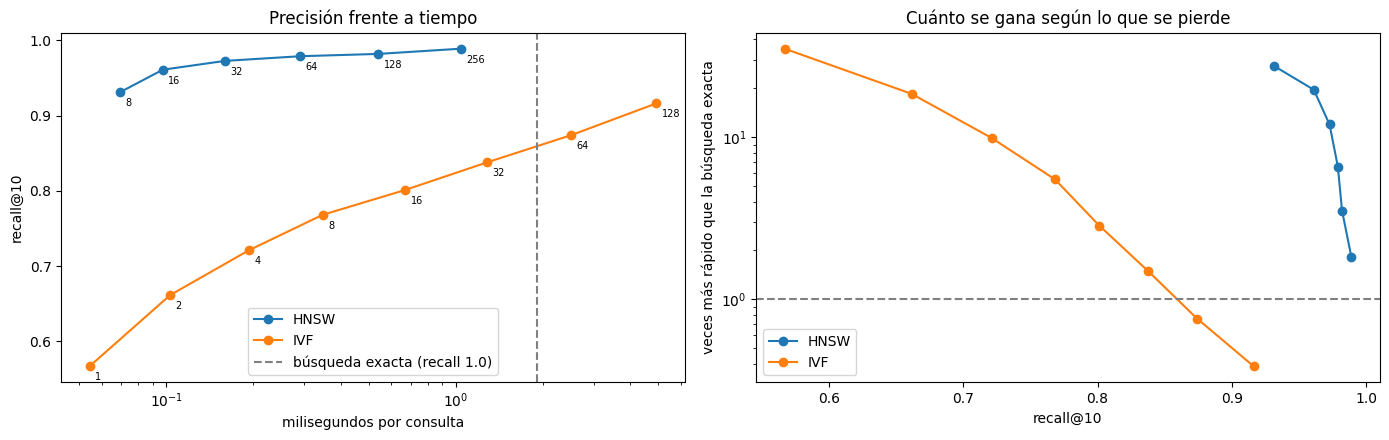

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
for metodo, g in resultados.groupby("metodo"):
    ejes[0].plot(g["ms_por_consulta"], g["recall_10"], "o-", label=metodo)
    for _, f in g.iterrows():
        ejes[0].annotate(int(f["valor"]), (f["ms_por_consulta"], f["recall_10"]), textcoords="offset points", xytext=(4, -10), fontsize=7)
ejes[0].axvline(ms_exacto, color="gray", ls="--", label="búsqueda exacta (recall 1.0)")
ejes[0].set_xscale("log"); ejes[0].set_xlabel("milisegundos por consulta"); ejes[0].set_ylabel("recall@10"); ejes[0].set_title("Precisión frente a tiempo"); ejes[0].legend()

for metodo, g in resultados.groupby("metodo"):
    ejes[1].plot(g["recall_10"], g["veces_mas_rapido"], "o-", label=metodo)
ejes[1].axhline(1, color="gray", ls="--"); ejes[1].set_yscale("log")
ejes[1].set_xlabel("recall@10"); ejes[1].set_ylabel("veces más rápido que la búsqueda exacta"); ejes[1].set_title("Cuánto se gana según lo que se pierde"); ejes[1].legend()
plt.tight_layout(); plt.show()

In [13]:
resumen = pd.DataFrame([
    {"método": "Exacta (fuerza bruta)", "construcción (s)": 0, "índice (MB)": tam_exacto, "ms por consulta": ms_exacto},
    {"método": f"IVF ({NLIST} listas)", "construcción (s)": t_ivf, "índice (MB)": tam_ivf, "ms por consulta": np.nan},
    {"método": f"HNSW (M={M})", "construcción (s)": t_hnsw, "índice (MB)": tam_hnsw, "ms por consulta": np.nan}]).round(1)
resumen

,método,construcción (s),índice (MB),ms por consulta
0,Exacta (fuerza bruta),0.0,334.3,1.9
1,IVF (512 listas),9.7,336.6,NaN
2,HNSW (M=32),88.7,378.7,NaN


### Lectura de la tarea 11
- **HNSW gana claramente.** Con `efSearch = 16` encuentra el 96.1% de los vecinos reales y es unas 20 veces más rápido que la búsqueda exacta (0.097 contra 1.91 ms). Con 64 llega a 97.9% (unas 6.6 veces más rápido) y con 256 a 98.9% (1.8 veces más rápido).
- **IVF no funciona bien con estos vectores.** Con `nprobe = 1` es 35 veces más rápido, pero solo encuentra el 56.7%. Con `nprobe = 32` llega a 83.8% y todavía es 1.5 veces más rápido. Desde `nprobe = 64` (87.4%) ya es **más lento que la búsqueda exacta**, y con 128 de las 512 listas llega a 91.6% pero es 2.6 veces más lento. Incluso `efSearch = 8` de HNSW (93.1%, 0.069 ms) supera a `nprobe = 128` de IVF (91.6%, 4.9 ms). Una explicación probable, que no verificamos, es que los textos no forman grupos bien separados en 512 dimensiones y los vecinos reales quedan repartidos entre varias listas.
- **Costos:** HNSW tarda mucho más en construirse (89 s contra 10 s de IVF) y ocupa un 13% más que los vectores solos (379 contra 334 MB).
- **¿Vale la pena?** Con 163 mil textos la búsqueda exacta tarda unos 2 ms por consulta, así que para una consulta suelta no hace falta nada más. HNSW se justifica con muchas consultas o con muchos más datos: la búsqueda exacta crece en proporción al número de vectores, y HNSW en general crece mucho más lento (aquí no lo medimos).
- **Qué se pierde:** con `efSearch = 16` se pierde cerca del 4% de los vecinos reales.
- **Cuidado con la lectura:** TF-IDF compara palabras, no significado. Por ejemplo, la consulta "sistema de sonido para el proyecto mejoramiento de los servicios operativos o misionales..." tiene como primer vecino (0.70) una compra de equipos de cómputo, porque comparten la frase de plantilla del proyecto. Los parlantes de sonido, que sí se parecen en significado, quedan terceros (0.40).
- **Los milisegundos dependen de la máquina.** Estos valores se midieron en Colab, con un solo hilo. En otra máquina serán otros, pero la comparación entre métodos debería parecerse.

## 4. Ejemplos de consultas
Veinte consultas con sus 5 vecinos exactos y los 5 que devuelve HNSW (con `efSearch = 16`). Sirven para ver qué textos considera parecidos y en qué casos el método aproximado se equivoca.

In [14]:
hnsw.hnsw.efSearch = 16
Q20 = Q[:20]
_, I = hnsw.search(Q20, K + 1)
vecinos_hnsw = [[j for j in fila if j != q][:5] for fila, q in zip(I, ids_consulta[:20])]
vecinos_exactos = [list(v[:5]) for v in verdad[:20]]

ejemplos = []
for q, ex, ap in zip(ids_consulta[:20], vecinos_exactos, vecinos_hnsw):
    ejemplos.append({
        "consulta": textos[q],
        "vecinos_exactos": [{"texto": textos[j], "similitud": round(float(V[q] @ V[j]), 3)} for j in ex],
        "vecinos_hnsw":    [{"texto": textos[j], "similitud": round(float(V[q] @ V[j]), 3)} for j in ap],
        "coinciden_en_top5": len(set(ex) & set(ap))})

e = ejemplos[0]
print("CONSULTA:", e["consulta"][:110])
for v in e["vecinos_exactos"][:3]:
    print(f"   {v['similitud']:.2f}  {v['texto'][:105]}")
print("coinciden en el top 5:", e["coinciden_en_top5"], "de 5")

CONSULTA: adquisicion de sistema de sonido para el proyecto mejoramiento de los servicios operativos o misionales instit
   0.70  adquisicion de equipos de computo para el proyecto mejoramiento de los servicios operativos o misionales 
   0.46  adquisicion de camaras para el proyecto mejoramiento de los servicios operativos o misionales institucion
   0.40  adquisicion de parlantes de sonido para la oficina de abastecimiento de la municipalidad de comas
coinciden en el top 5: 5 de 5


In [15]:
# Archivos para la página web (módulo ANN)
calidad = {"solape_top10_reducido_vs_completo": round(float(solape), 3),
           "jaccard_vecino1_tfidf_completo": round(float(j1_completo), 3), "jaccard_vecino1_reducido": round(float(j1_reducido), 3)}

guardar_json("ann_curvas.json",
    {"titulo": "Búsqueda aproximada de vecinos: precisión frente a tiempo",
     "descripcion": "Para cada valor del parámetro de búsqueda de IVF (nprobe) y de HNSW (efSearch): recall@10 y milisegundos por consulta, frente a la búsqueda exacta.",
     "n_vectores": int(len(V)), "dimensiones": DIM, "k": K, "n_consultas": N_CONSULTAS,
     "exacta": {"ms_por_consulta": round(float(ms_exacto), 3), "recall_10": 1.0},
     "campos": {"metodo": "IVF o HNSW", "parametro": "nprobe (IVF) o efSearch (HNSW)", "valor": "valor del parámetro",
                "recall_10": "de los 10 vecinos reales, fracción que encontró el método", "ms_por_consulta": "tiempo promedio por consulta, un hilo",
                "veces_mas_rapido": "ms de la búsqueda exacta / ms del método"},
     "nota": "Los milisegundos dependen de la máquina. Las comparaciones entre métodos sí son válidas."},
    a_registros(resultados.round(4)))

guardar_json("ann_resumen.json",
    {"titulo": "Resumen de la búsqueda de vecinos", "descripcion": "Parámetros, tiempos de construcción y tamaños de los índices.",
     "campos": {"construccion_s": "segundos que tarda armar el índice", "indice_mb": "tamaño del índice en MB"}},
    [{"metodo": "Exacta", "construccion_s": 0, "indice_mb": round(tam_exacto, 1), "ms_por_consulta": round(float(ms_exacto), 3)},
     {"metodo": "IVF", "construccion_s": round(t_ivf, 1), "indice_mb": round(tam_ivf, 1), "listas": NLIST},
     {"metodo": "HNSW", "construccion_s": round(t_hnsw, 1), "indice_mb": round(tam_hnsw, 1), "m": M, "ef_construccion": EF_CONSTRUCCION},
     {"metodo": "Representación", "textos": int(len(V)), "dimensiones": DIM, "vocabulario_tfidf": int(X.shape[1]), **calidad}])

guardar_json("ann_ejemplos.json",
    {"titulo": "Ejemplos de consultas", "descripcion": "Consultas con sus 5 vecinos exactos y los 5 que devuelve HNSW (efSearch = 16). Similitud = coseno.",
     "campos": {"consulta": "texto consultado", "vecinos_exactos": "los 5 más parecidos (búsqueda exacta)", "vecinos_hnsw": "los 5 que devolvió HNSW",
                "coinciden_en_top5": "cuántos de los 5 coinciden"}, "nota": "Solo texto de los procesos; no incluye proveedores."},
    ejemplos)

ann_curvas.json: 14 registros, 3 KB
ann_resumen.json: 4 registros, 1 KB
ann_ejemplos.json: 20 registros, 49 KB
